# R-GCN link prediction: depth check

**Question.** Is the KG difference in link prediction a matter of path length? Each target's prediction
depends on a few literals that identify the answer, and a K-layer model sees only nodes within K hops of the
query head. The schemas fix how many hops away those literals are (`link_prediction_tools.evidence_hops`;
a direct property is 1 hop, a SULO path 2):

| Evidence (from the query head) | Ad-hoc | Hybrid | Pure |
|---|---|---|---|
| Team: the driver's literals (entry → driver → name, ...) | 2 | 2 | 4 |
| Position: a session's rank (entry → session → Position → rank) | 3 | 4 | 4 |
| Circuit: the race's literals (race → name, ...) | 1 | 1 | 2 |

At the main runs' K = 3 (R-GCN Pure: K = 2), this matches every R-GCN result: Team Ad-hoc 0.727 / Hybrid 0.721 /
Pure 0.267, Position 0.405 / 0.277 / 0.235, Circuit ≈ 0.93 everywhere. The LP ablation showed that Hybrid's lower
Position comes from `rank_reification` alone, the unit that adds the fourth hop. The hop table is a hypothesis
until a deeper model closes the gaps, so this notebook runs **K = 4**.

**Predictions (stated before the run):**
- **Hybrid Position** rises to about Ad-hoc's level (≈ 0.44 test MRR): at K = 4 a session's rank is within reach.
- **Pure Team and Pure Position** rise clearly at K = 4 (the driver's literals and a session's rank are 4 hops away).
  If Pure Team stays near 0.27, path length does not explain Pure's Team result, and Pure's shared predicates
  (driver and team both behind `hasParticipant → Role → isFeatureOf`) remain the candidate cause.
- **Ad-hoc** at K = 4 ≈ K = 3: everything it needs is within 3 hops, which rules out "deeper is simply better".
- **Circuit** stays ≈ 0.93 in every KG (its evidence is within 2 hops).

**Protocol: the LP ablation's.** Every KG gets the Hybrid winner's configuration (dim, bases, lr, wd), and only the
depth changes (`hidden_list = [dim] * (K − 1)`). Each seed in `FINAL_SEEDS` trains on the train races with early
stopping on pooled val MRR after the 50-epoch warm-up, and the best-val weights are scored on the test races, with
train + val facts as context (`run_lp_ablation_variant`). The K = 3 rows of Ad-hoc and Hybrid are the ablation's
controls, reused after checking that their configuration matches. Pure is run at K = 3 here, because its main
run used its own 2-layer winner. Pure's tuning chose 2 layers at lr 1e-2 and bases 10, where no Pure config learned
(phase-1 val MRR ≤ 0.227), so the shared-config K = 3 run also checks whether Pure's main LP result was a search
artifact. No shuffled-answer check: these are the main notebooks' graphs, checked there. Limitation: the
400-epoch cap stays (59 of 60 ablation seeds peaked in the last 50 epochs). This notebook and
its GraphSAGE counterpart differ only in the encoder.

In [1]:
# Must run before CUDA is initialised: avoids fragmentation OOMs across a long sweep.
import os
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "f1_population.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from f1_node_data import load_population
from f1_population import SCHEMA_FILES, read_schema
from link_prediction.link_prediction_tools import (
    EVIDENCE_CHAINS, LP_ABLATION_METRICS, TARGETS, LinkPredictor, build_lp_data, evidence_hops, leaked_facts,
    race_split, run_lp_ablation_variant,
)
from node_prediction.gnn_tools import cleanup, limit_cuda_memory_to_free_vram, summarize_ablation
from node_prediction.models import RGCNModel

MAIN_DIR = ROOT / "outputs" / "f1" / "link_prediction" / "rgcn"
ABLATION_CSV = ROOT / "outputs" / "f1" / "link_prediction" / "ablation" / "rgcn" / "ablation_results.csv"
OUT_DIR = ROOT / "outputs" / "f1" / "link_prediction" / "depth" / "rgcn"
OUT_DIR.mkdir(parents=True, exist_ok=True)
KGS = ["adhoc", "hybrid_sulo", "pure_sulo"]
print(torch.__version__, "| CUDA:", torch.cuda.is_available())
# WSL2 would otherwise overcommit VRAM into RAM and fail with a driver error instead of an OOM,
# which the run could not skip.
if torch.cuda.is_available():
    print(f"CUDA memory cap: {limit_cuda_memory_to_free_vram() / 2**30:.2f} GiB")

/home/domin/miniconda3/envs/sulo/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2.7.0+cu126 | CUDA: True
CUDA memory cap: 10.48 GiB


## Data

The three KGs exactly as in the main notebooks (`build_lp_data`, shared race split), with the leak check at both
hiding stages (training: val + test races; test: test races). The hop table is computed from the schemas.

In [2]:
entities, assertions = load_population(ROOT / "data" / "f1")
split = race_split(entities, seed=42)
schemas = {kg: read_schema(str(ROOT / path)) for kg, path in SCHEMA_FILES.items()}
lp_data = {kg: build_lp_data(kg, entities, assertions, split, schemas[kg]) for kg in KGS}
for kg, d in lp_data.items():
    for hidden in (d.race_split >= 1, d.race_split == 2):
        leaks = leaked_facts(d, hidden)
        assert set(leaks.values()) == {0}, f"{kg} leaks hidden facts: {leaks}"

pd.DataFrame({kg: {name: evidence_hops(schemas[kg], chain) for name, chain in EVIDENCE_CHAINS.items()}
              for kg in KGS}).rename_axis("hops to the evidence")

,adhoc,hybrid_sulo,pure_sulo
hops to the evidence,,,
"LP team: the driver's literals, from the entry",2,2,4
"LP team: the team's literals, from a candidate",1,1,2
"LP position: a session's rank, from the entry",3,4,4
"LP position: the rank, from a candidate",1,2,2
"LP circuit: the race's literals, from the race",1,1,2
"LP circuit: the circuit's literals, from a candidate",1,1,2
NP: the entry's own grid rank,2,3,3


## Constants

The training constants are the main notebook's (`link_prediction_rgcn.ipynb`), with the same sources; the
configuration is the Hybrid winner of its tuning run, read from its CSV.

In [3]:
# Full-batch, so one epoch = one gradient step. Max epochs 400 = the top of GraphGym's design space
# {100, 200, 400} (You et al. 2020, Section 4). Patience 50: no literature value (user choice,
# 2026-10-21, as in node prediction). Same values as the main notebooks.
#   https://arxiv.org/abs/2011.08843
EPOCHS = 400
PATIENCE = 50

# Early-stopping warm-up (user, 2026-10-29, as in node prediction): epochs 0-49 are trained but neither
# checkpointed nor counted towards patience, as Keras' EarlyStopping(start_from_epoch). No literature value.
#   https://keras.io/api/callbacks/early_stopping/
START_FROM_EPOCH = 50

# Node input embedding size: the GraphSAGE reference implementation recommends learned identity
# features of 64-256 dims (README, --identity_dim). Also the embedding dim of a 1-layer model.
#   https://github.com/williamleif/GraphSAGE#readme
FEATURE_DIM = 256

# Dropout: PyG's R-GCN example uses p=0.2 between the RGCNConv layers; the original
# R-GCN paper uses no dropout for entity classification.
#   https://github.com/pyg-team/pytorch_geometric/blob/master/examples/rgcn_link_pred.py
DROPOUT = 0.2

# Share of the training races whose target facts are hidden from message passing and supervised in an
# epoch (redrawn every epoch; the rest are context). User choice (2026-11-02): 0.3 is the value of PyG's
# link-prediction tutorial for RandomLinkSplit(disjoint_train_ratio), which exists to keep supervision
# edges out of message passing; R-GCN's link-prediction edge dropout of 0.4 is the closest value from
# Schlichtkrull et al. 2018.
#   https://pytorch-geometric.readthedocs.io/en/latest/generated/torch_geometric.transforms.RandomLinkSplit.html
#   https://arxiv.org/abs/1703.06103
DISJOINT_TRAIN_RATIO = 0.3

# The main notebooks' final-evaluation seeds (user, 2026-10-20); results are mean ± std over them.
FINAL_SEEDS = [0, 1, 2, 3, 4]

config_columns = ["hidden_dim", "layers", "num_bases", "lr", "weight_decay"]


def phase4_winner(kg):
    """A KG's tuned configuration: its phase-4 rows (one per final seed) must agree on it."""
    rows = pd.read_csv(MAIN_DIR / f"{kg}_sequential_tuning_results.csv").query("phase == '4_Final_Test_Evaluation'")
    assert len(rows.drop_duplicates(config_columns)) == 1, f"{kg}: phase-4 rows disagree on the configuration"
    return rows.iloc[0]


# Fixed configuration: the Hybrid winner, as in the LP ablation; only the depth K changes.
winner = phase4_winner("hybrid_sulo")
DIM = int(winner["hidden_dim"])
BASES = None if pd.isna(winner["num_bases"]) else int(winner["num_bases"])
assert BASES is None or all(BASES <= d.num_relations for d in lp_data.values()), "bases > R in a KG"
LR, WD = float(winner["lr"]), float(winner["weight_decay"])
assert int(winner["layers"]) == 3, "the reused K = 3 controls assume a 3-layer Hybrid winner"

# K = 3 for Ad-hoc and Hybrid is not re-run: it is the LP ablation's two controls (same configuration,
# seeds, protocol and graphs). Pure has no ablation control, so it runs at K = 3 here too.
RUNS = {3: ["pure_sulo"], 4: ["adhoc", "hybrid_sulo", "pure_sulo"]}
print(f"Hybrid winner: dim {DIM}, bases {BASES}, lr {LR}, wd {WD}; depths {RUNS}")

Hybrid winner: dim 64, bases 2, lr 0.005, wd 0.0; depths {3: ['pure_sulo'], 4: ['adhoc', 'hybrid_sulo', 'pure_sulo']}


In [4]:
def model_factory(d):
    """(hidden_list, bases) -> fresh LinkPredictor for one KG; everything KG-specific is bound here.
    The embedding dim is the last hidden dim; a 1-layer model has none and embeds in FEATURE_DIM."""
    def build(hidden_list, bases):
        dim = hidden_list[-1] if hidden_list else FEATURE_DIM
        encoder = RGCNModel(
            num_keys=len(d.vocabulary), feature_dim=FEATURE_DIM, hidden_channels_list=hidden_list,
            num_relations=d.num_relations, num_bases=bases, out_channels=dim, dropout=DROPOUT,
        )
        return LinkPredictor(encoder, len(TARGETS), dim)
    return build

## Depth runs

One CSV per depth (`K3.csv`, `K4.csv`), because `run_lp_ablation_variant` requires one configuration per CSV;
the variant label is the KG. Rows are appended as each seed finishes: after a crash, finished (KG, seed) pairs
are skipped and failed ones retried. Constants are not checked, so move the CSVs away after changing one.

In [5]:
for K, kgs in RUNS.items():
    for kg in kgs:
        run_lp_ablation_variant(
            model_factory(lp_data[kg]), lp_data[kg], kg, [DIM] * (K - 1), BASES, LR, WD,
            epochs=EPOCHS, patience=PATIENCE, start_from_epoch=START_FROM_EPOCH,
            disjoint_ratio=DISJOINT_TRAIN_RATIO, seeds=FINAL_SEEDS,
            save_dir=f"{OUT_DIR / 'checkpoints' / f'K{K}'}/", csv_path=OUT_DIR / f"K{K}.csv",
        )
        cleanup()


def same_config(rows, dim, layers):
    """True if every row ran (dim, layers) with BASES, LR and WD."""
    expected = [dim, layers, np.nan if BASES is None else BASES, LR, WD]
    return all(np.allclose(row.astype(float), expected, equal_nan=True) for _, row in rows[config_columns].iterrows())


reused = pd.read_csv(ABLATION_CSV).query("variant in ['adhoc', 'hybrid_sulo'] and seed in @FINAL_SEEDS").assign(K=3)
assert same_config(reused, DIM, 3), "the ablation's controls ran another configuration"
results = pd.concat([reused, *(pd.read_csv(OUT_DIR / f"K{K}.csv").assign(K=K) for K in RUNS)], ignore_index=True)
results = results.rename(columns={"variant": "kg"})
results["variant"] = results["kg"] + "_K" + results["K"].astype(str)

failed = results[results["status"] != "ok"]
assert failed.empty, f"Runs that did not finish:\n{failed[['variant', 'seed', 'status']]}"
seeds = results.groupby("variant")["seed"].apply(sorted)
assert len(seeds) == 2 * len(KGS) and all(s == FINAL_SEEDS for s in seeds), f"every KG x K needs every seed:\n{seeds}"
assert all(same_config(results[results["K"] == K], DIM, K) for K in (3, 4))
early = results[results["best_epoch"] < START_FROM_EPOCH]
assert early.empty, f"Rows selected inside the warm-up:\n{early[['variant', 'seed', 'best_epoch']]}"


=== LP ablation pure_sulo | seed 0 ===
Epoch 000 | Train Loss: 7.2056 | Val MRR: 0.1193 (team 0.0806, position 0.1615, circuit 0.0882) | Grad Norm: 24.8331
Epoch 001 | Train Loss: 5.3027 | Val MRR: 0.1387 (team 0.1135, position 0.1676, circuit 0.0865) | Grad Norm: 9.7179
Epoch 002 | Train Loss: 4.7946 | Val MRR: 0.1348 (team 0.1049, position 0.1678, circuit 0.1065) | Grad Norm: 6.2207
Epoch 003 | Train Loss: 4.6036 | Val MRR: 0.1386 (team 0.1121, position 0.1678, circuit 0.1103) | Grad Norm: 3.4349
Epoch 004 | Train Loss: 4.3600 | Val MRR: 0.1483 (team 0.1313, position 0.1678, circuit 0.1147) | Grad Norm: 1.9639
Epoch 005 | Train Loss: 4.2967 | Val MRR: 0.1690 (team 0.1723, position 0.1678, circuit 0.1219) | Grad Norm: 1.5993
Epoch 006 | Train Loss: 4.2990 | Val MRR: 0.1816 (team 0.1977, position 0.1678, circuit 0.1161) | Grad Norm: 1.4744
Epoch 007 | Train Loss: 4.2467 | Val MRR: 0.1874 (team 0.2101, position 0.1678, circuit 0.0935) | Grad Norm: 1.4846
Epoch 008 | Train Loss: 4.1656 

## Results

Mean ± std over `FINAL_SEEDS` per KG and depth, and the difference of each K = 4 mean from the same KG at K = 3
(`delta_*`, pooled and per target). Differences are reported as mean ± std, with no significance test (as in
the main notebooks).

In [6]:
controls = {f"{kg}_K{K}": f"{kg}_K3" for kg in KGS for K in (3, 4)}
summary = summarize_ablation(results, controls, metrics=LP_ABLATION_METRICS, delta_metrics=LP_ABLATION_METRICS)
summary.round(4).to_csv(OUT_DIR / "depth_summary.csv")
summary.round(4)

,control,n_seeds,val_mrr_mean,val_mrr_std,test_mrr_mean,test_mrr_std,test_team_mrr_mean,test_team_mrr_std,test_position_mrr_mean,test_position_mrr_std,test_circuit_mrr_mean,test_circuit_mrr_std,delta_val_mrr,delta_test_mrr,delta_test_team_mrr,delta_test_position_mrr,delta_test_circuit_mrr
variant,,,,,,,,,,,,,,,,,
adhoc_K3,adhoc_K3,5,0.5858,0.0361,0.5758,0.0352,0.7184,0.0102,0.4090,0.0761,0.9166,0.0169,0.0000,0.0000,0.0000,0.0000,0.0000
adhoc_K4,adhoc_K3,5,0.5968,0.0147,0.5861,0.0167,0.6987,0.0242,0.4524,0.0168,0.9004,0.0154,0.0110,0.0103,-0.0197,0.0434,-0.0163
hybrid_sulo_K3,hybrid_sulo_K3,5,0.5156,0.0032,0.5102,0.0047,0.7151,0.0074,0.2738,0.0028,0.9279,0.0079,0.0000,0.0000,0.0000,0.0000,0.0000
hybrid_sulo_K4,hybrid_sulo_K3,5,0.5447,0.0461,0.5396,0.0442,0.7097,0.0053,0.3428,0.0896,0.8967,0.0073,0.0291,0.0294,-0.0054,0.0690,-0.0313
pure_sulo_K3,pure_sulo_K3,5,0.2981,0.0084,0.2871,0.0124,0.3163,0.0124,0.2410,0.0057,0.6205,0.2309,0.0000,0.0000,0.0000,0.0000,0.0000
pure_sulo_K4,pure_sulo_K3,5,0.3851,0.0229,0.3722,0.0245,0.4815,0.0406,0.2586,0.0083,0.3162,0.1637,0.0870,0.0851,0.1652,0.0176,-0.3043


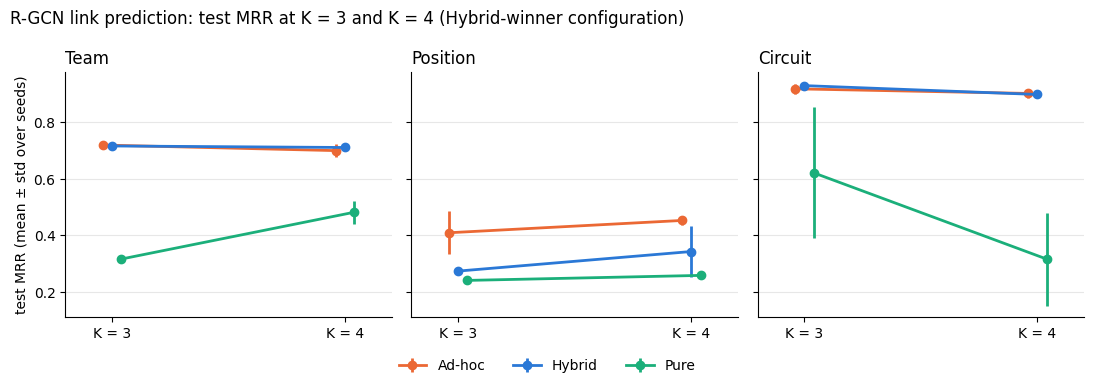

In [7]:
# Validated default categorical palette (dataviz skill), one fixed colour per KG.
colors = {"adhoc": "#eb6834", "hybrid_sulo": "#2a78d6", "pure_sulo": "#1baf7a"}
names = {"adhoc": "Ad-hoc", "hybrid_sulo": "Hybrid", "pure_sulo": "Pure"}
fig, axes = plt.subplots(1, len(TARGETS), figsize=(11, 3.8), sharey=True)
for ax, target in zip(axes, TARGETS):
    metric = f"test_{target}_mrr"
    for i, kg in enumerate(KGS):
        rows = summary.loc[[f"{kg}_K3", f"{kg}_K4"]]
        x = np.array([3, 4]) + (i - 1) * 0.04          # a small offset keeps equal points apart
        ax.errorbar(x, rows[f"{metric}_mean"], yerr=rows[f"{metric}_std"], color=colors[kg], marker="o",
                    markersize=6, linewidth=2, capsize=0, label=names[kg])
    ax.set_title(target.capitalize(), loc="left")
    ax.set_xticks([3, 4], ["K = 3", "K = 4"])
    ax.set_xlim(2.8, 4.2)
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("test MRR (mean ± std over seeds)")
fig.legend(*axes[0].get_legend_handles_labels(), frameon=False, loc="lower center", ncol=3)
fig.suptitle("R-GCN link prediction: test MRR at K = 3 and K = 4 (Hybrid-winner configuration)", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(OUT_DIR / "depth_test_mrr.png", dpi=200)
plt.show()

## Limitation: runs ended by the epoch cap

A seed whose best epoch is ≥ `EPOCHS − PATIENCE` was cut off by the `EPOCHS` cap while possibly still
improving, so its score may be understated (the same limitation as in the main notebooks).

In [8]:
results[results["best_epoch"] >= EPOCHS - PATIENCE][["variant", "seed", "best_epoch", "val_mrr", "test_mrr",
                                                        *(f"test_{t}_mrr" for t in TARGETS)]]

,variant,seed,best_epoch,val_mrr,test_mrr,test_team_mrr,test_position_mrr,test_circuit_mrr
0,hybrid_sulo_K3,0,376,0.515724,0.508139,0.709368,0.275302,0.932238
1,hybrid_sulo_K3,1,396,0.519769,0.516017,0.724013,0.276298,0.933310
2,hybrid_sulo_K3,2,393,0.514450,0.508950,0.712806,0.274143,0.914807
3,hybrid_sulo_K3,3,387,0.511077,0.504190,0.707615,0.269103,0.926429
4,hybrid_sulo_K3,4,393,0.517058,0.513920,0.721662,0.274396,0.932902
5,adhoc_K3,0,394,0.604558,0.594921,0.723525,0.443511,0.923794
7,adhoc_K3,2,389,0.595191,0.585951,0.725375,0.423873,0.896490
8,adhoc_K3,3,385,0.521760,0.513457,0.721912,0.274347,0.906447
9,adhoc_K3,4,399,0.607588,0.597902,0.720767,0.451961,0.940705
10,pure_sulo_K3,0,389,0.301004,0.279738,0.306854,0.233925,0.657373
